# Chapter 9 · Transformations of random vectors: interactive demos

Companion to Chapter 9 of the notes [*Probability with Measure Theory*](https://gennaroalberto.github.io/probability-measure-theory/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/probability-measure-theory/blob/main/code/notebooks/09-random-vectors.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/probability-measure-theory#subdirectory=code"

import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from probnotes.vectors import (beta_pdf, binomial_pmf, convolve_pmfs, dkw_sample_size, empirical_cdf,
                               gamma_pdf, geometric_pmf, joint_cdf_gap, ks_distance,
                               linear_transformed_density, pascal_pmf, poisson_pmf, sample_correlation,
                               sample_gamma_beta, sample_worked, uniform_product_cdf, uniform_product_pdf)
from probnotes.style import COBALT, GOLD, GREY, INK, use_style

GREEN = "#1BAF7A"
use_style()

## 1. Sums of discrete variables: the discrete convolution

For independent $X$ and $Y$ with values in $\mathbb N$, $f_{X+Y}(t)=\sum_{x=0}^tf_X(x)f_Y(t-x)=(f_X*f_Y)(t)$ (Proposition 9.2),
which is `numpy.convolve` of the two arrays of probabilities. The bars are the convolution, the dots the notable law
predicted by Proposition 9.3 ($\mathcal P(\lambda+\mu)$, $B(n+m,p)$, $\mathrm{Pascal}(n+m,p)$), and the grey steps the
relative frequencies of $X+Y$ in simulated pairs. For two fair dice the law of the sum is the familiar triangle.

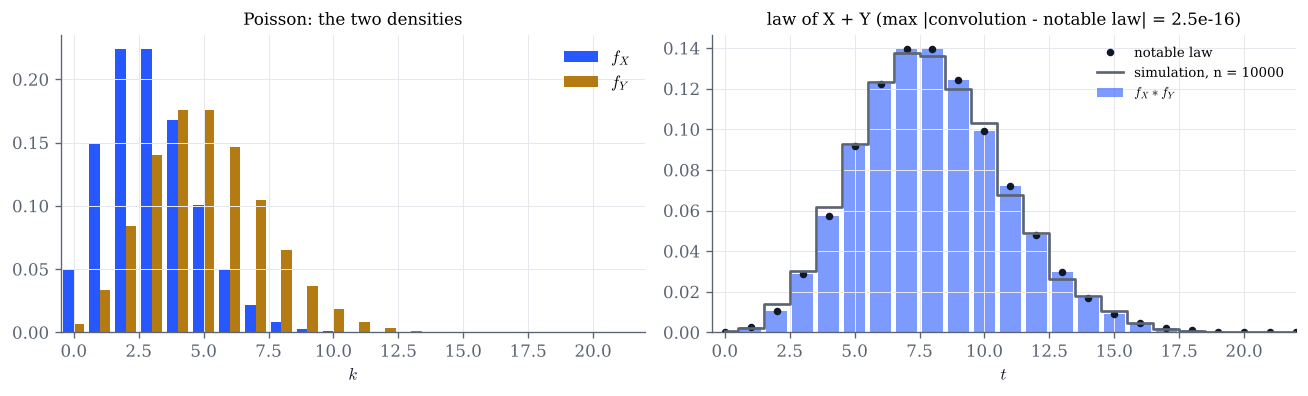

In [2]:
def law(family, a, p, k):
    if family == "Poisson":
        return poisson_pmf(k, a)
    if family == "binomial":
        return binomial_pmf(k, int(a), p)
    if family == "Pascal":
        return pascal_pmf(k, int(a), p)
    return np.where((k >= 1) & (k <= int(a)), 1.0 / int(a), 0.0)      # uniform on {1, ..., a}: a die

def draw(family, a, p, rng, n):
    if family == "Poisson":
        return rng.poisson(a, n)
    if family == "binomial":
        return rng.binomial(int(a), p, n)
    if family == "Pascal":
        return int(a) + rng.negative_binomial(int(a), p, n)          # trial of the a-th success
    return rng.integers(1, int(a) + 1, n)

def convolution_demo(family="Poisson", a=3.0, b=5.0, p=0.4, log10_n=4.0, seed=2026):
    if family in ("binomial", "Pascal", "die"):
        a, b = max(1, round(a)), max(1, round(b))
    K = 80
    k = np.arange(K)
    fx, fy = law(family, a, p, k), law(family, b, p, k)
    r, _ = convolve_pmfs(fx, fy)
    r = r[:K]
    pred = {"Poisson": poisson_pmf(k, a + b), "binomial": binomial_pmf(k, int(a + b), p),
            "Pascal": pascal_pmf(k, int(a + b), p)}.get(family)
    rng = np.random.default_rng(seed)
    n = int(10 ** log10_n)
    s = draw(family, a, p, rng, n) + draw(family, b, p, rng, n)
    freq = np.bincount(s, minlength=K)[:K] / n
    top = max(int(np.max(k[(fx + fy + r) > 1e-4])) + 2, 8)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4))
    a1.bar(k - 0.2, fx, width=0.4, color=COBALT, label="$f_X$")
    a1.bar(k + 0.2, fy, width=0.4, color=GOLD, label="$f_Y$")
    a1.set(xlim=(-0.5, top), xlabel="$k$", title=f"{family}: the two densities")
    a1.legend()
    a2.bar(k, r, width=0.8, color=COBALT, alpha=0.6, label="$f_X * f_Y$")
    if pred is not None:
        a2.plot(k, pred, "o", color=INK, ms=3.5, label="notable law")
        err = np.max(np.abs(pred - r))
    else:
        err = float("nan")
    a2.step(k, freq, where="mid", color=GREY, label=f"simulation, n = {n}")
    a2.set(xlim=(-0.5, top), xlabel="$t$", title=f"law of X + Y (max |convolution - notable law| = {err:.1e})")
    a2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

convolution_demo()

In [3]:
# Explore: for "die", a and b are the numbers of faces of the two dice.
interact(convolution_demo,
         family=Dropdown(options=["Poisson", "binomial", "Pascal", "die"], value="Poisson", description="law"),
         a=FloatSlider(value=3.0, min=0.5, max=15, step=0.5, continuous_update=False, description="lambda / n"),
         b=FloatSlider(value=5.0, min=0.5, max=15, step=0.5, continuous_update=False, description="mu / m"),
         p=FloatSlider(value=0.4, min=0.05, max=0.95, step=0.05, continuous_update=False, description="p"),
         log10_n=FloatSlider(value=4.0, min=2.0, max=6.0, step=0.5, continuous_update=False, description="log10 n"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## 2. The Jacobian formula for a linear map

For an invertible matrix $A$, $W=AZ+b$ has density $f_W(w)=\frac1{|\det A|}f_Z\big(A^{-1}(w-b)\big)$ (Theorem 9.8, Example 9.9).
Left: samples of $W$ and the contour lines of $f_W$. Right: the histogram of the first coordinate $U$ of $W$ against the
marginal density $\int f_W(u,v)\,dv$, computed numerically from the formula. The components of $Z$ are independent, with
the chosen law. As $\det A\to0$ the density concentrates near a line: for $\det A=0$, $W$ has no density at all.

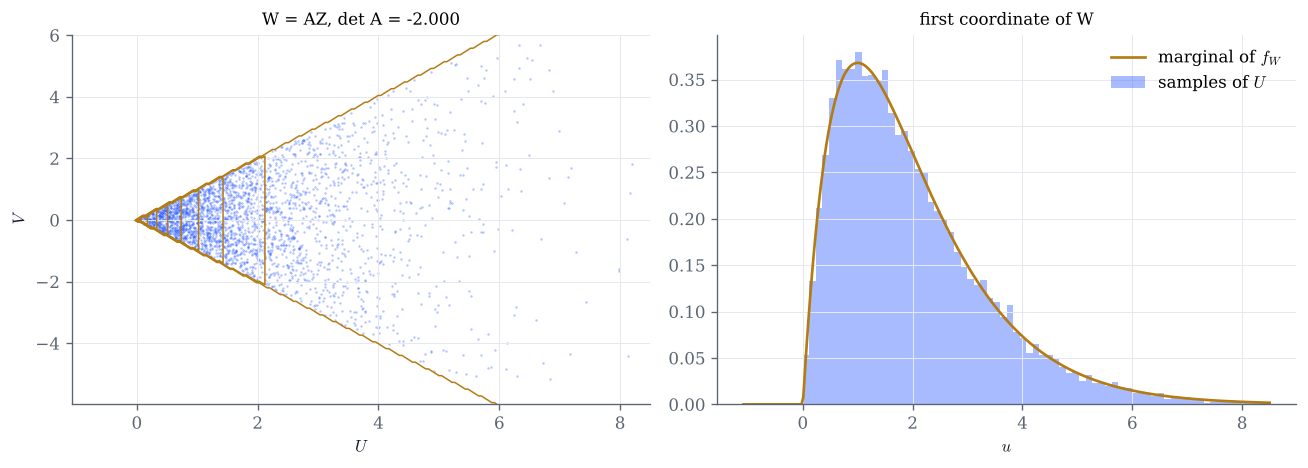

In [4]:
BASE = {"exponential": (lambda x: gamma_pdf(x, 1, 1.0), lambda rng, n: rng.exponential(1.0, n)),
        "uniform": (lambda x: ((x > 0) & (x < 1)).astype(float), lambda rng, n: rng.random(n)),
        "Gaussian": (lambda x: np.exp(-x * x / 2) / np.sqrt(2 * np.pi), lambda rng, n: rng.normal(size=n))}

def jacobian_demo(base="exponential", a11=1.0, a12=1.0, a21=1.0, a22=-1.0, n=20000, seed=2026):
    A = np.array([[a11, a12], [a21, a22]])
    det = np.linalg.det(A)
    f1, draw1 = BASE[base]
    rng = np.random.default_rng(seed)
    z = np.vstack([draw1(rng, n), draw1(rng, n)])
    w = A @ z
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
    lo, hi = np.quantile(w, [0.005, 0.995], axis=1)
    pad = 0.15 * (hi - lo) + 0.1
    lo, hi = lo - pad, hi + pad
    a1.scatter(w[0, :3000], w[1, :3000], s=2, color=COBALT, alpha=0.35, lw=0)
    if abs(det) > 1e-3:
        fW = linear_transformed_density(lambda x, y: f1(x) * f1(y), A)
        U, V = np.meshgrid(np.linspace(lo[0], hi[0], 220), np.linspace(lo[1], hi[1], 220))
        a1.contour(U, V, fW(U, V), levels=8, colors=[GOLD], linewidths=0.9)
        v = np.linspace(lo[1] - 10, hi[1] + 10, 6000)
        u = np.linspace(lo[0], hi[0], 300)
        dv = v[1] - v[0]
        marg = np.array([np.sum(fW(np.full_like(v, uu), v)) * dv for uu in u])
        a2.plot(u, marg, color=GOLD, label="marginal of $f_W$")
    a1.set(xlim=(lo[0], hi[0]), ylim=(lo[1], hi[1]), xlabel="$U$", ylabel="$V$", title=f"W = AZ, det A = {det:.3f}")
    a2.hist(w[0], bins=80, range=(lo[0], hi[0]), density=True, color=COBALT, alpha=0.4, label="samples of $U$")
    a2.set(xlabel="$u$", title="first coordinate of W")
    a2.legend()
    fig.tight_layout()
    plt.show()

jacobian_demo()

In [5]:
# Explore: A = [[1, 1], [1, -1]] gives (X + Y, X - Y); with Gaussian components the two are independent.
s = dict(min=-2.0, max=2.0, step=0.1, continuous_update=False)
interact(jacobian_demo,
         base=Dropdown(options=list(BASE), value="exponential", description="law of Z_i"),
         a11=FloatSlider(value=1.0, description="a11", **s), a12=FloatSlider(value=1.0, description="a12", **s),
         a21=FloatSlider(value=1.0, description="a21", **s), a22=FloatSlider(value=-1.0, description="a22", **s),
         n=IntSlider(value=20000, min=2000, max=200000, step=2000, continuous_update=False, description="n"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## 3. Gamma and Beta: independent, not just uncorrelated

For independent $X\sim\Gamma(\alpha,\lambda)$ and $Y\sim\Gamma(\beta,\lambda)$, $S=X+Y\sim\Gamma(\alpha+\beta,\lambda)$ and
$T=X/(X+Y)\sim\mathrm{Beta}(\alpha,\beta)$ are independent (Proposition 9.15). Here $Y$ has its own rate $\mu$: the
dashed curves are the laws predicted when $\mu=\lambda$. The panel on the right compares the joint distribution function
of $(S,T)$ with the product of the marginal ones, over a grid of sample quantiles: for an independent pair the largest gap
tends to $0$ like $n^{-1/2}$ (Remark 9.17). Move $\mu$ away from $\lambda$ and watch the gap stay away from $0$.

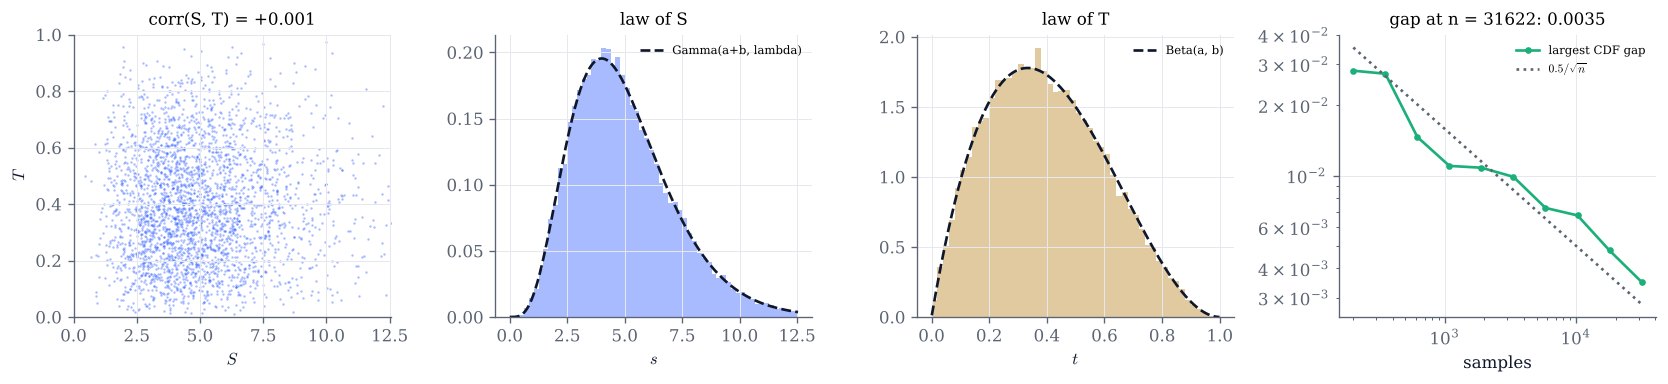

In [6]:
def gamma_beta_demo(alpha=2.0, beta=3.0, lam=1.0, mu=1.0, log10_n=4.5, seed=2026):
    n = int(10 ** log10_n)
    s, t = sample_gamma_beta(alpha, beta, lam, n, seed, lam2=mu)
    fig, axes = plt.subplots(1, 4, figsize=(14, 3.3))
    m = min(n, 3000)
    axes[0].scatter(s[:m], t[:m], s=2, color=COBALT, alpha=0.4, lw=0)
    axes[0].set(xlabel="$S$", ylabel="$T$", ylim=(0, 1), xlim=(0, np.quantile(s, 0.995)),
                title=f"corr(S, T) = {sample_correlation(s, t):+.3f}")
    g = np.linspace(1e-3, np.quantile(s, 0.995), 400)
    axes[1].hist(s, bins=60, range=(0, g[-1]), density=True, color=COBALT, alpha=0.4)
    axes[1].plot(g, gamma_pdf(g, alpha + beta, lam), color=INK, ls="--", label="Gamma(a+b, lambda)")
    axes[1].set(xlabel="$s$", title="law of S")
    axes[1].legend(fontsize=7)
    u = np.linspace(1e-3, 1 - 1e-3, 400)
    axes[2].hist(t, bins=50, range=(0, 1), density=True, color=GOLD, alpha=0.4)
    axes[2].plot(u, beta_pdf(u, alpha, beta), color=INK, ls="--", label="Beta(a, b)")
    axes[2].set(xlabel="$t$", title="law of T")
    axes[2].legend(fontsize=7)
    sizes = np.unique(np.geomspace(200, n, 10).astype(int))
    gaps = [joint_cdf_gap(s[:k], t[:k]) for k in sizes]
    axes[3].plot(sizes, gaps, color=GREEN, marker="o", ms=3, label="largest CDF gap")
    axes[3].plot(sizes, 0.5 / np.sqrt(sizes), color=GREY, ls=":", label="$0.5/\\sqrt{n}$")
    axes[3].set(xscale="log", yscale="log", xlabel="samples", title=f"gap at n = {n}: {gaps[-1]:.4f}")
    axes[3].legend(fontsize=7)
    fig.tight_layout()
    plt.show()

gamma_beta_demo()

In [7]:
interact(gamma_beta_demo,
         alpha=FloatSlider(value=2.0, min=0.2, max=8.0, step=0.1, continuous_update=False, description="alpha"),
         beta=FloatSlider(value=3.0, min=0.2, max=8.0, step=0.1, continuous_update=False, description="beta"),
         lam=FloatSlider(value=1.0, min=0.2, max=5.0, step=0.1, continuous_update=False, description="lambda"),
         mu=FloatSlider(value=1.0, min=0.2, max=5.0, step=0.1, continuous_update=False, description="mu (rate of Y)"),
         log10_n=FloatSlider(value=4.5, min=3.0, max=6.0, step=0.25, continuous_update=False, description="log10 n"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## 4. Products of uniforms

The product $U_n=X_1\cdots X_n$ of $n$ independent uniforms on $(0,1)$ has density $\frac{(-\log u)^{n-1}}{(n-1)!}$ on $(0,1)$
and distribution function $F_{U_n}(u)=u\sum_{k<n}\frac{(-\log u)^k}{k!}$ (Example 9.22, Exercise 9.6). The right panel shows the
empirical distribution function of $N$ samples with the band $F_{U_n}\pm\varepsilon$, where $N$ and $\varepsilon$ are related
by the Dvoretzky--Kiefer--Wolfowitz inequality: the empirical function leaves the band with probability at most $\delta$.

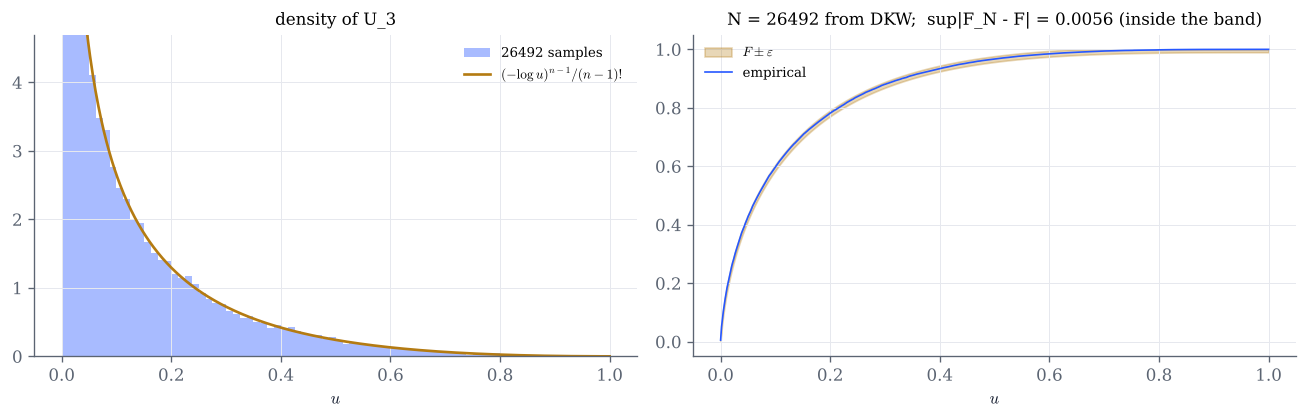

In [8]:
def products_demo(n=3, eps=0.01, delta=0.01, seed=2026):
    N = dkw_sample_size(eps, delta)
    u = sample_worked("uniform-product", N, seed=seed, m=n)
    d = ks_distance(u, lambda x: uniform_product_cdf(x, n))
    g = np.linspace(1e-4, 1, 600)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
    a1.hist(u, bins=80, range=(0, 1), density=True, color=COBALT, alpha=0.4, label=f"{N} samples")
    a1.plot(g, uniform_product_pdf(g, n), color=GOLD, label="$(-\\log u)^{n-1}/(n-1)!$")
    a1.set(xlabel="$u$", ylim=(0, min(12, 1.2 * np.max(uniform_product_pdf(g[50:], n)) + 1)), title=f"density of U_{n}")
    a1.legend(fontsize=8)
    F = uniform_product_cdf(g, n)
    a2.fill_between(g, np.clip(F - eps, 0, 1), np.clip(F + eps, 0, 1), color=GOLD, alpha=0.3, label="$F\\pm\\varepsilon$")
    a2.plot(g, empirical_cdf(u, g), color=COBALT, lw=1, label="empirical")
    a2.set(xlabel="$u$", title=f"N = {N} from DKW;  sup|F_N - F| = {d:.4f} ({'inside' if d <= eps else 'outside'} the band)")
    a2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

products_demo()

In [9]:
interact(products_demo,
         n=IntSlider(value=3, min=1, max=10, continuous_update=False, description="n"),
         eps=FloatSlider(value=0.01, min=0.002, max=0.05, step=0.002, readout_format=".3f", continuous_update=False, description="epsilon"),
         delta=FloatSlider(value=0.01, min=0.001, max=0.2, step=0.001, readout_format=".3f", continuous_update=False, description="delta"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## Things to try

- In section 1, choose Pascal with $n=m=1$: two geometric variables. Is their sum geometric? Which law is it?
- In section 1, take two dice with $6$ and $6$ faces, then $4$ and $9$ faces. Where is the law of the sum flat, and why?
- In section 2, take Gaussian components and $A=\begin{pmatrix}1&1\\1&-1\end{pmatrix}$: the contour lines are circles, and
  $X+Y$, $X-Y$ are independent. With exponential components the density lives on a wedge, with uniform ones on a
  square turned by $45^\circ$: why? (Compare the strip of Example 9.21.)
- In section 2, bring $a_{22}$ close to $a_{12}a_{21}/a_{11}$, so that $\det A\to0$. What happens to the density?
- In section 3, set $\alpha=\beta=1$: then $T$ is uniform. Set $\mu=3$: is the correlation still close to $0$? Is the gap?
- In section 4, how does $N$ grow when $\varepsilon$ is halved? When $\delta$ is divided by $10$? Count how often, over many
  seeds, the empirical function leaves the band.